<a href="https://colab.research.google.com/github/felipevergalr/calculo-numerico/blob/main/atividade_19_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sistemas lineares — Método de Gauss–Seidel

**Felipe Pereira Vergal Rostirola — RA: 185210**  
**Data: 19/10/2026**

Cálculo Numérico — Profa. Raquel Lobosco

## Questão 1

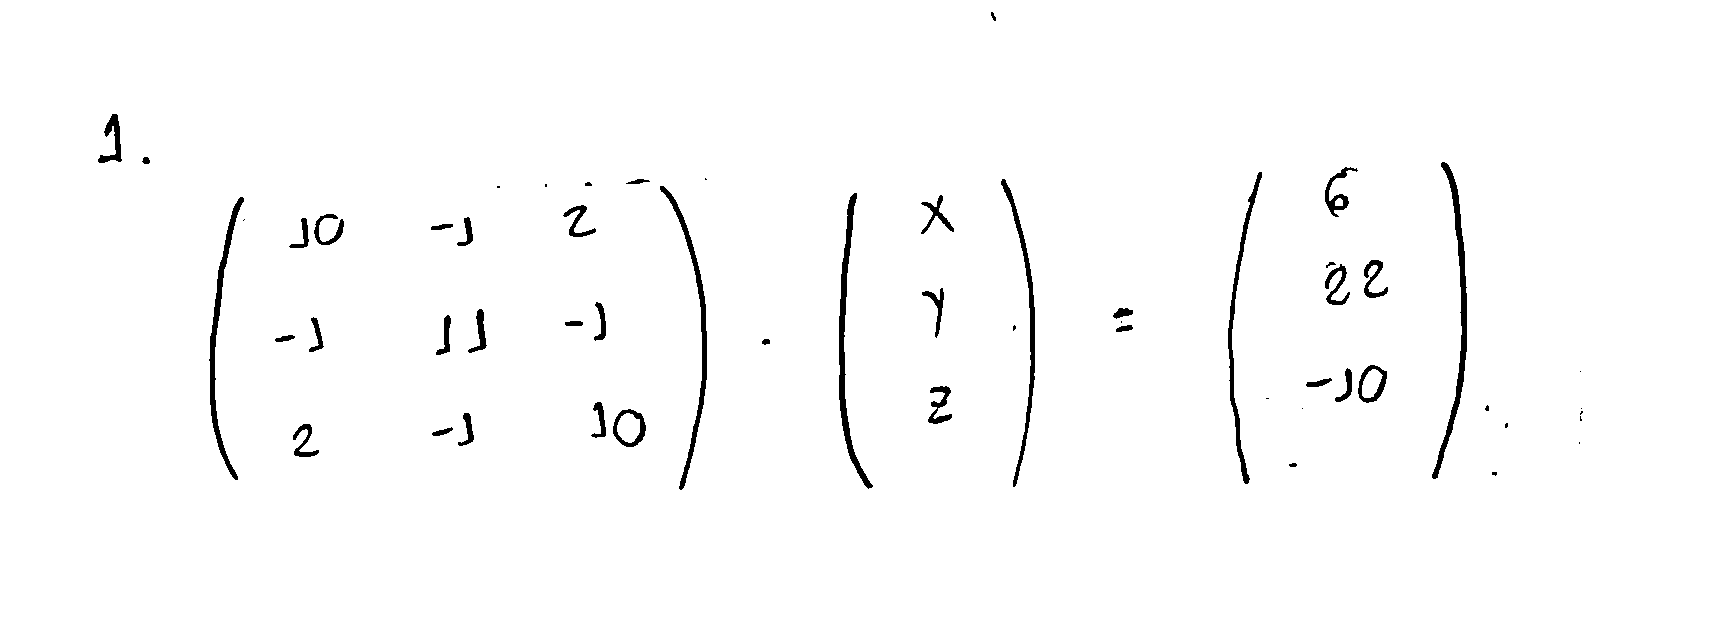



## Questão 2

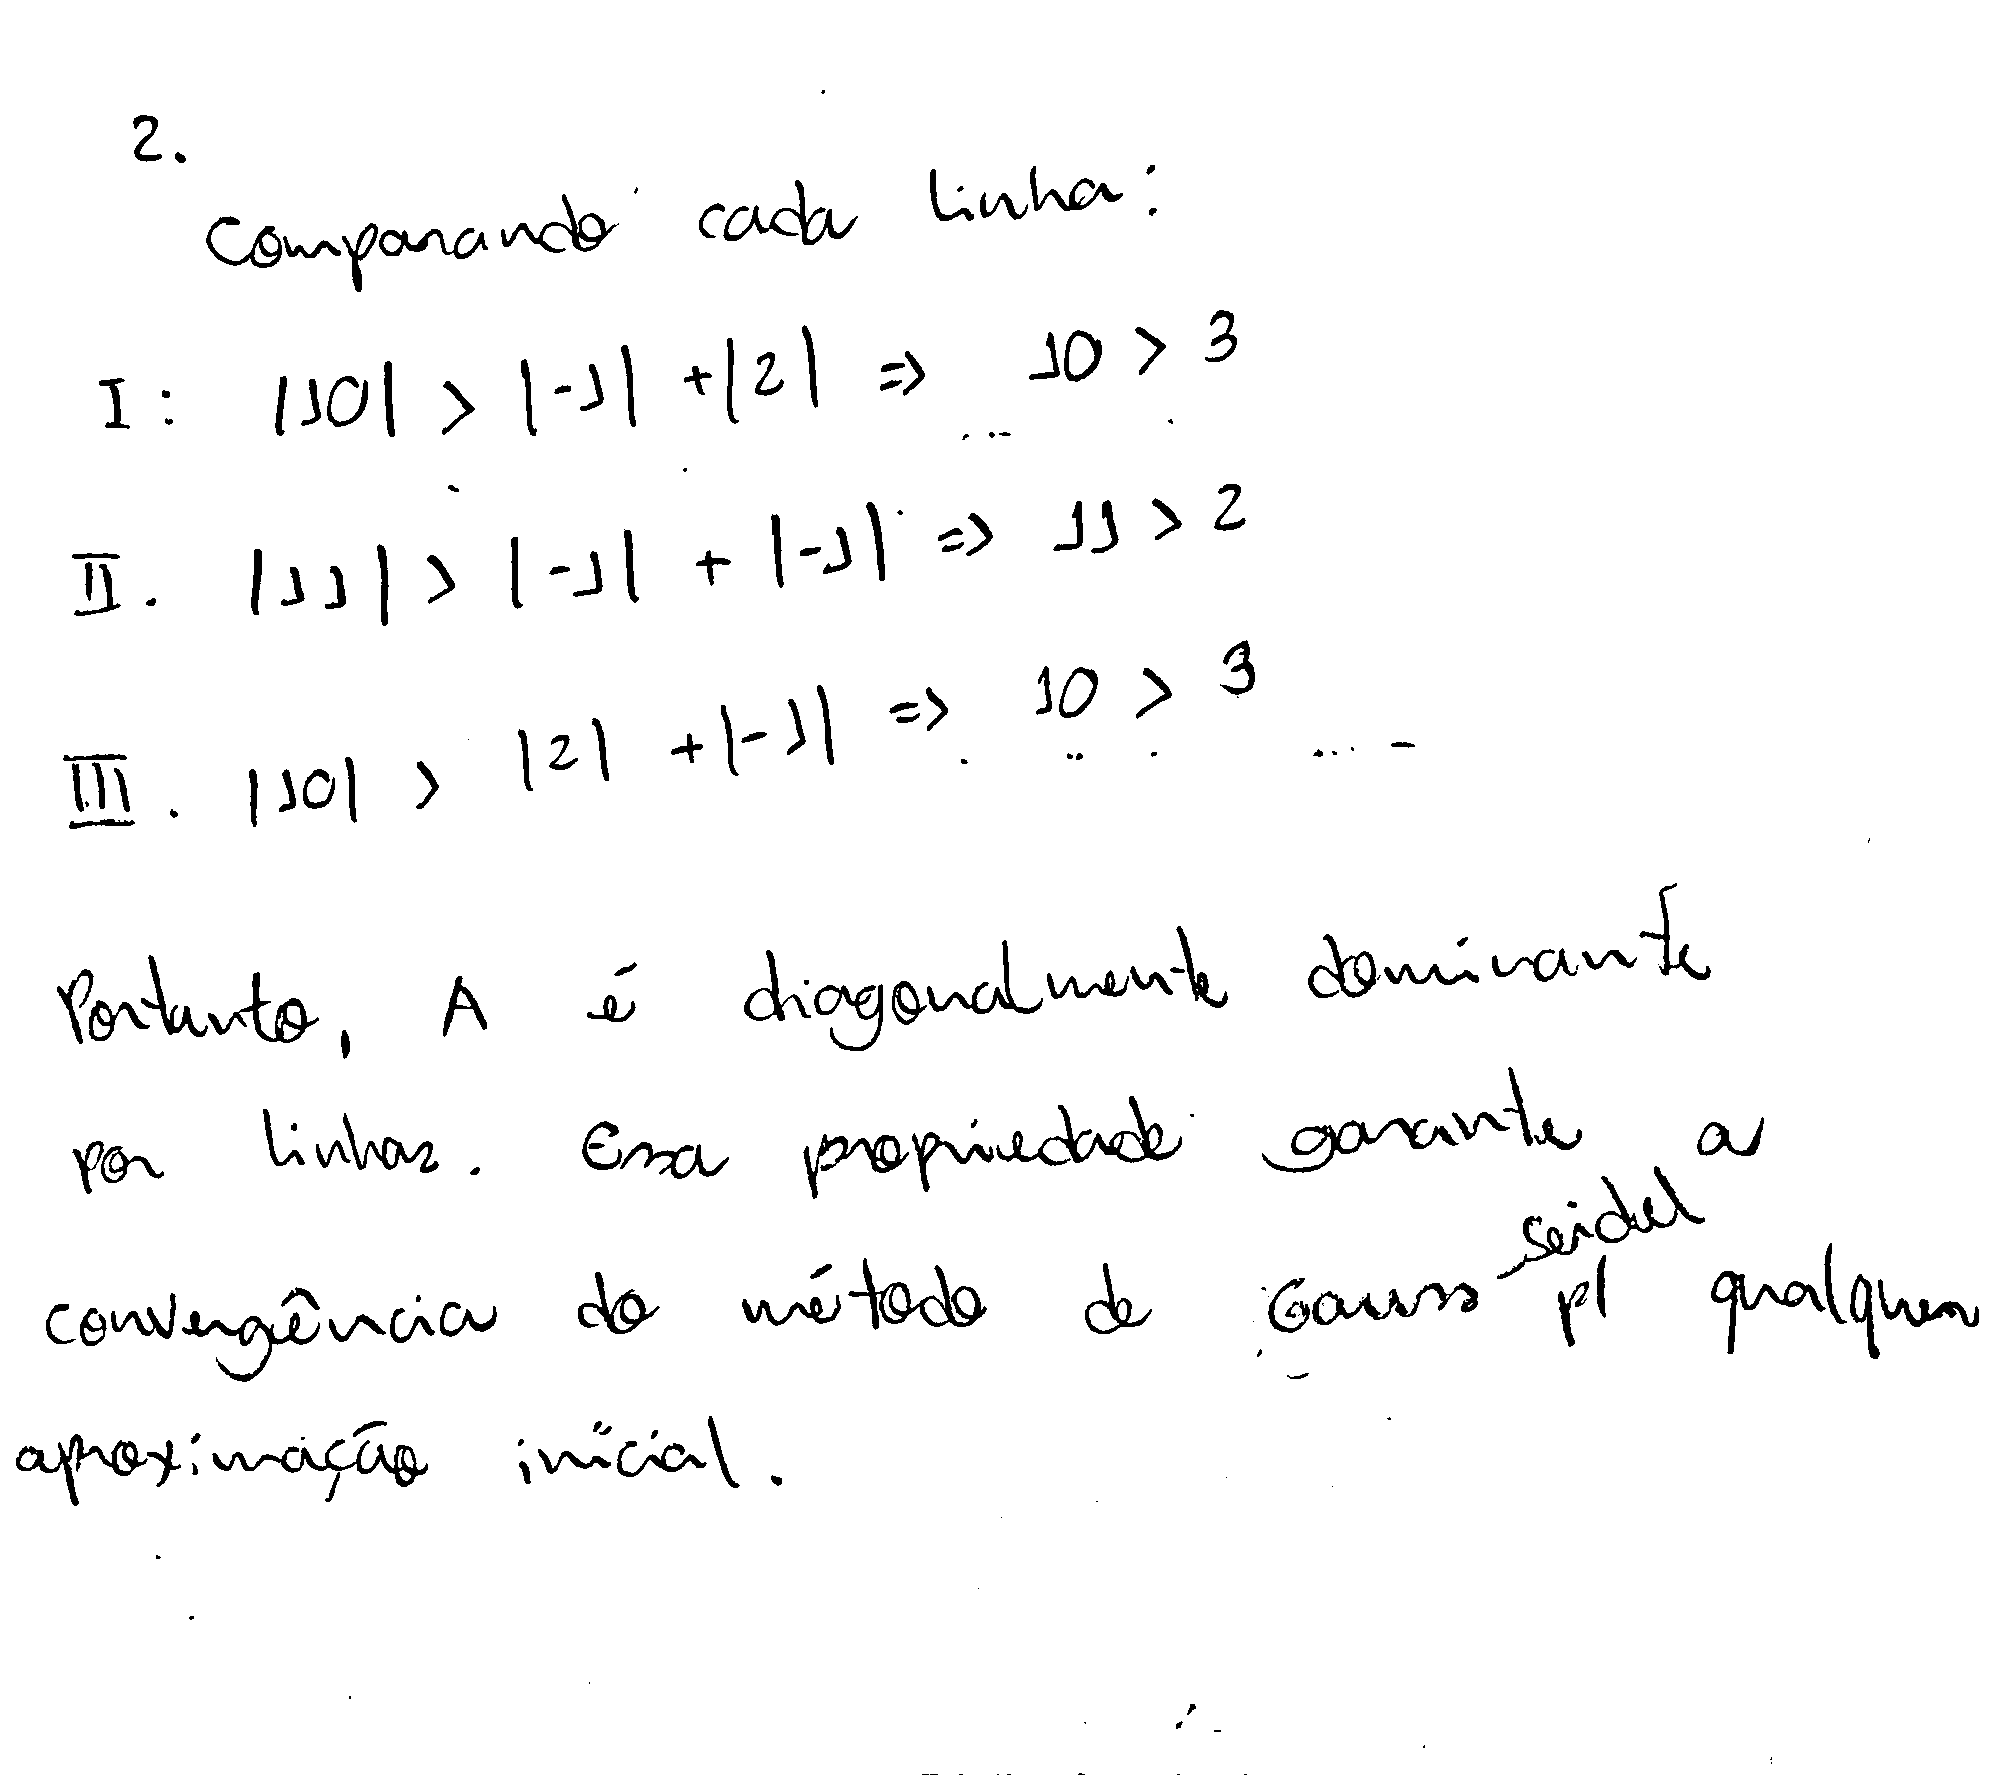



## Questão 3

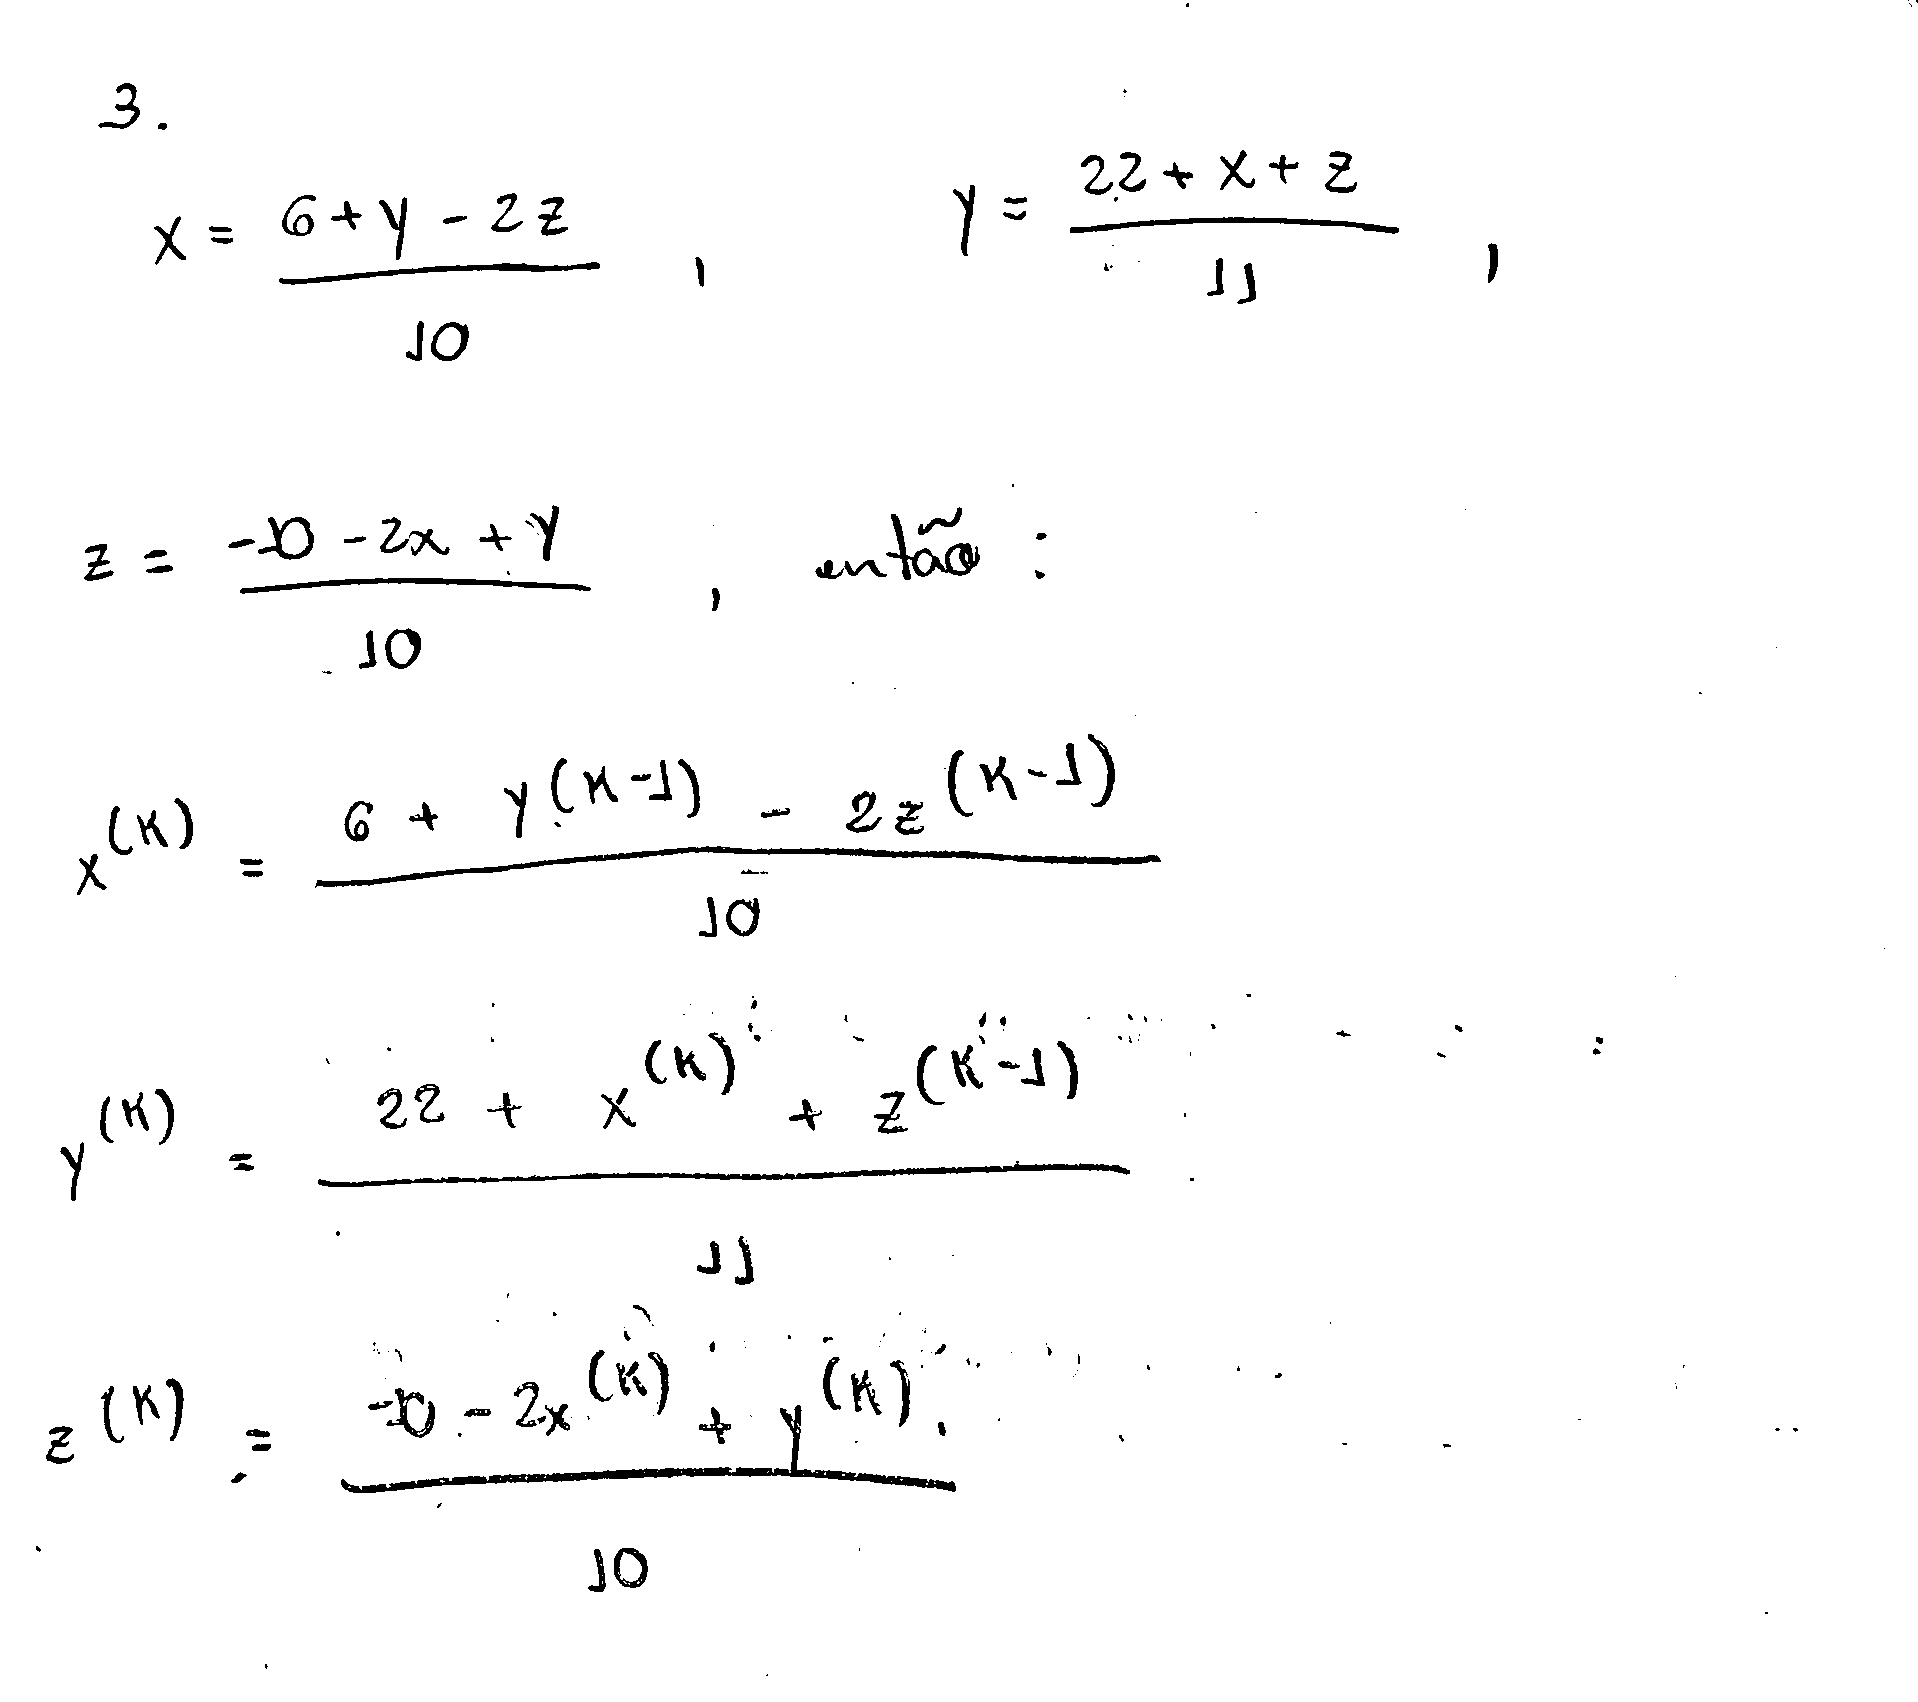



## Questão 4

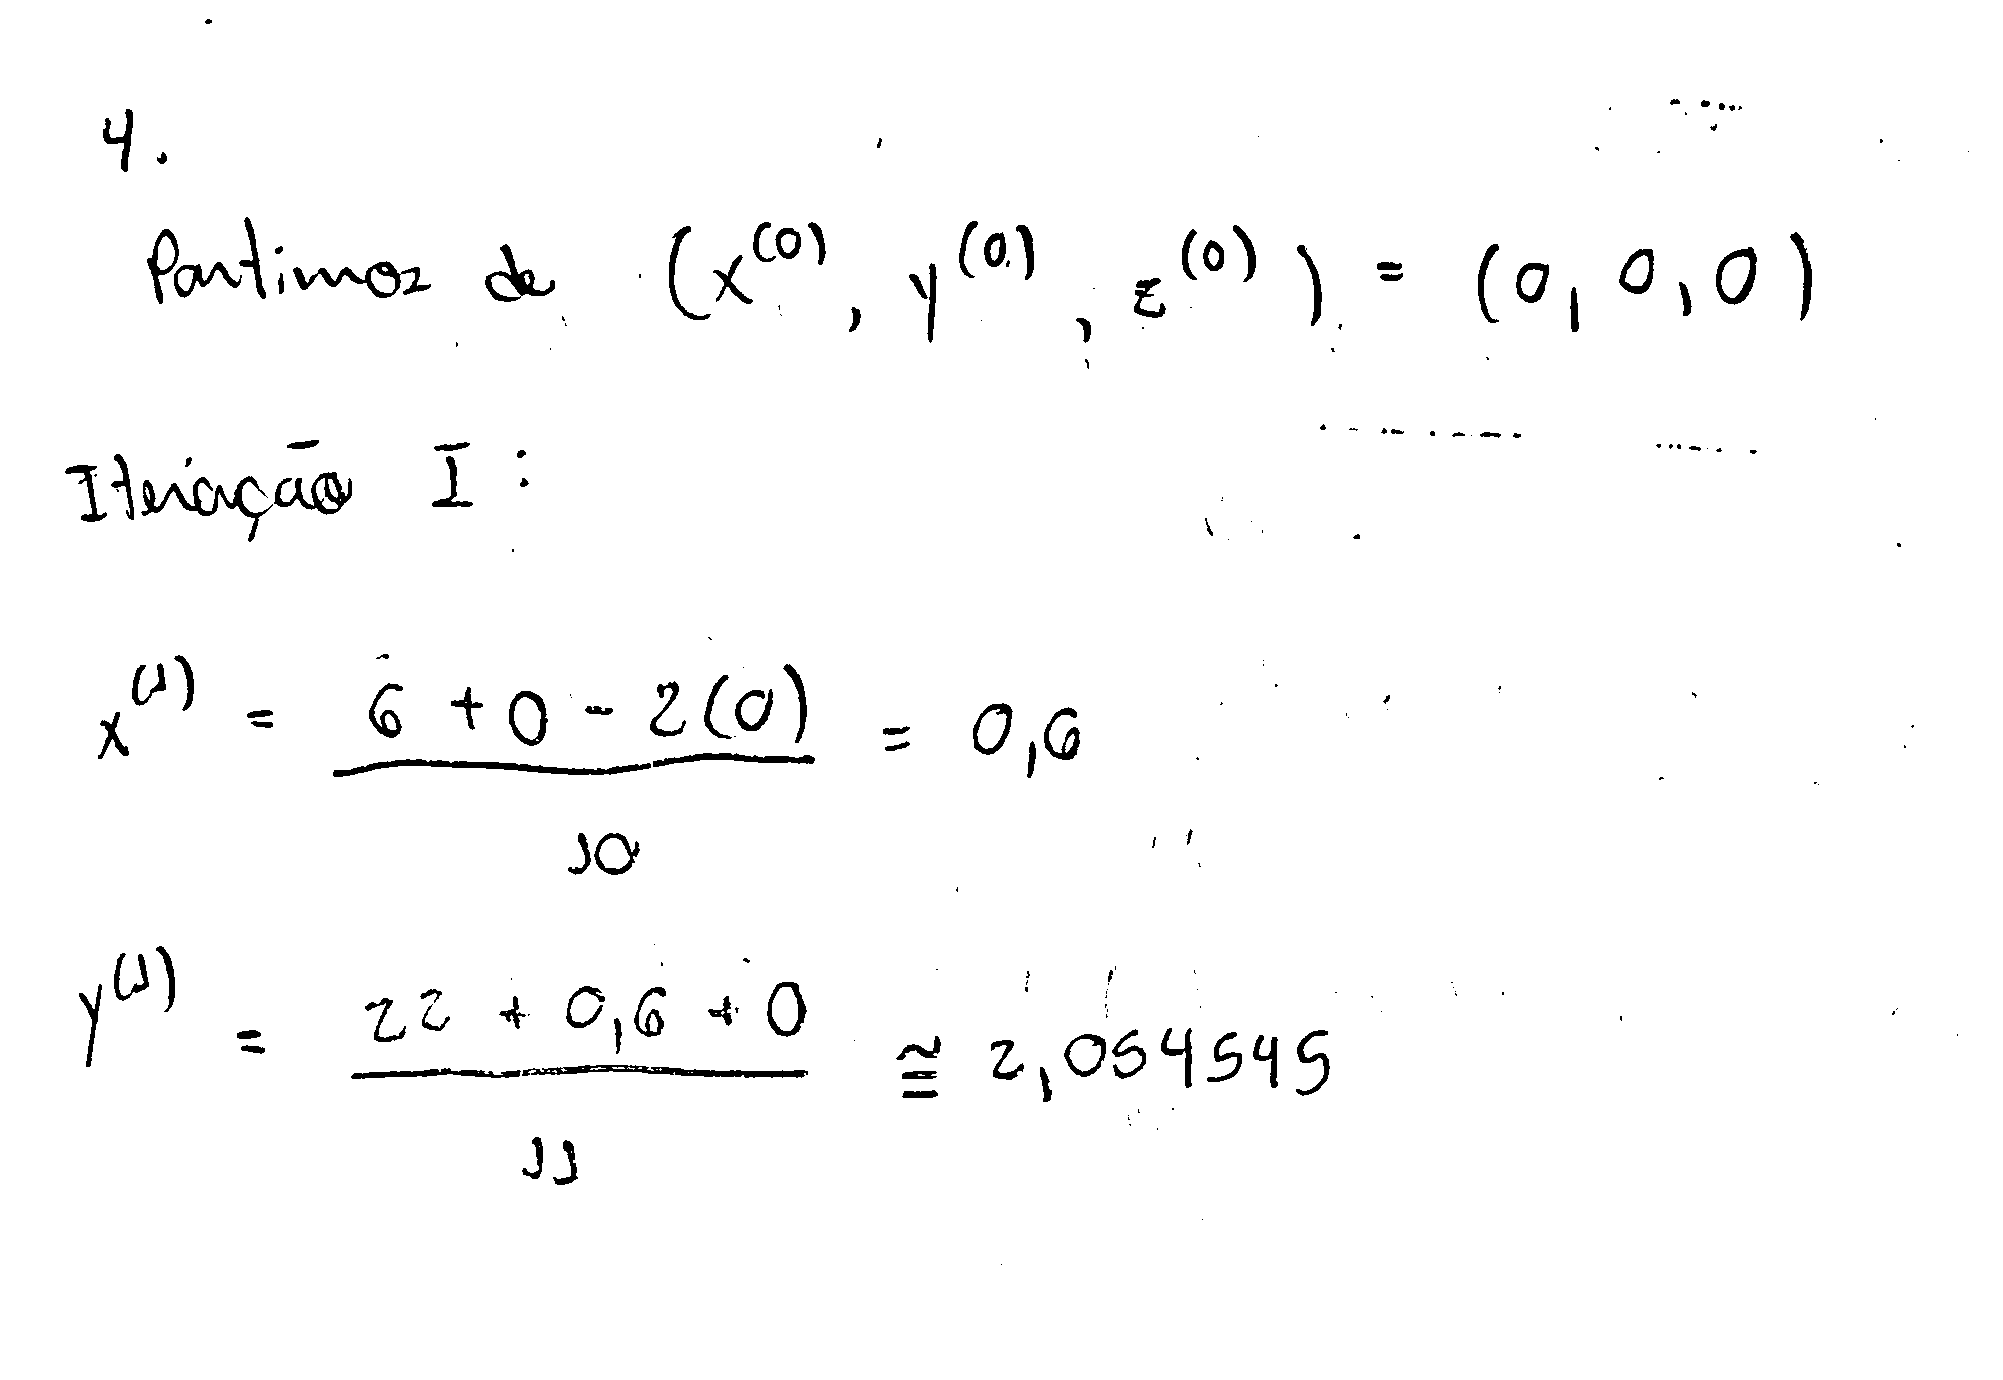

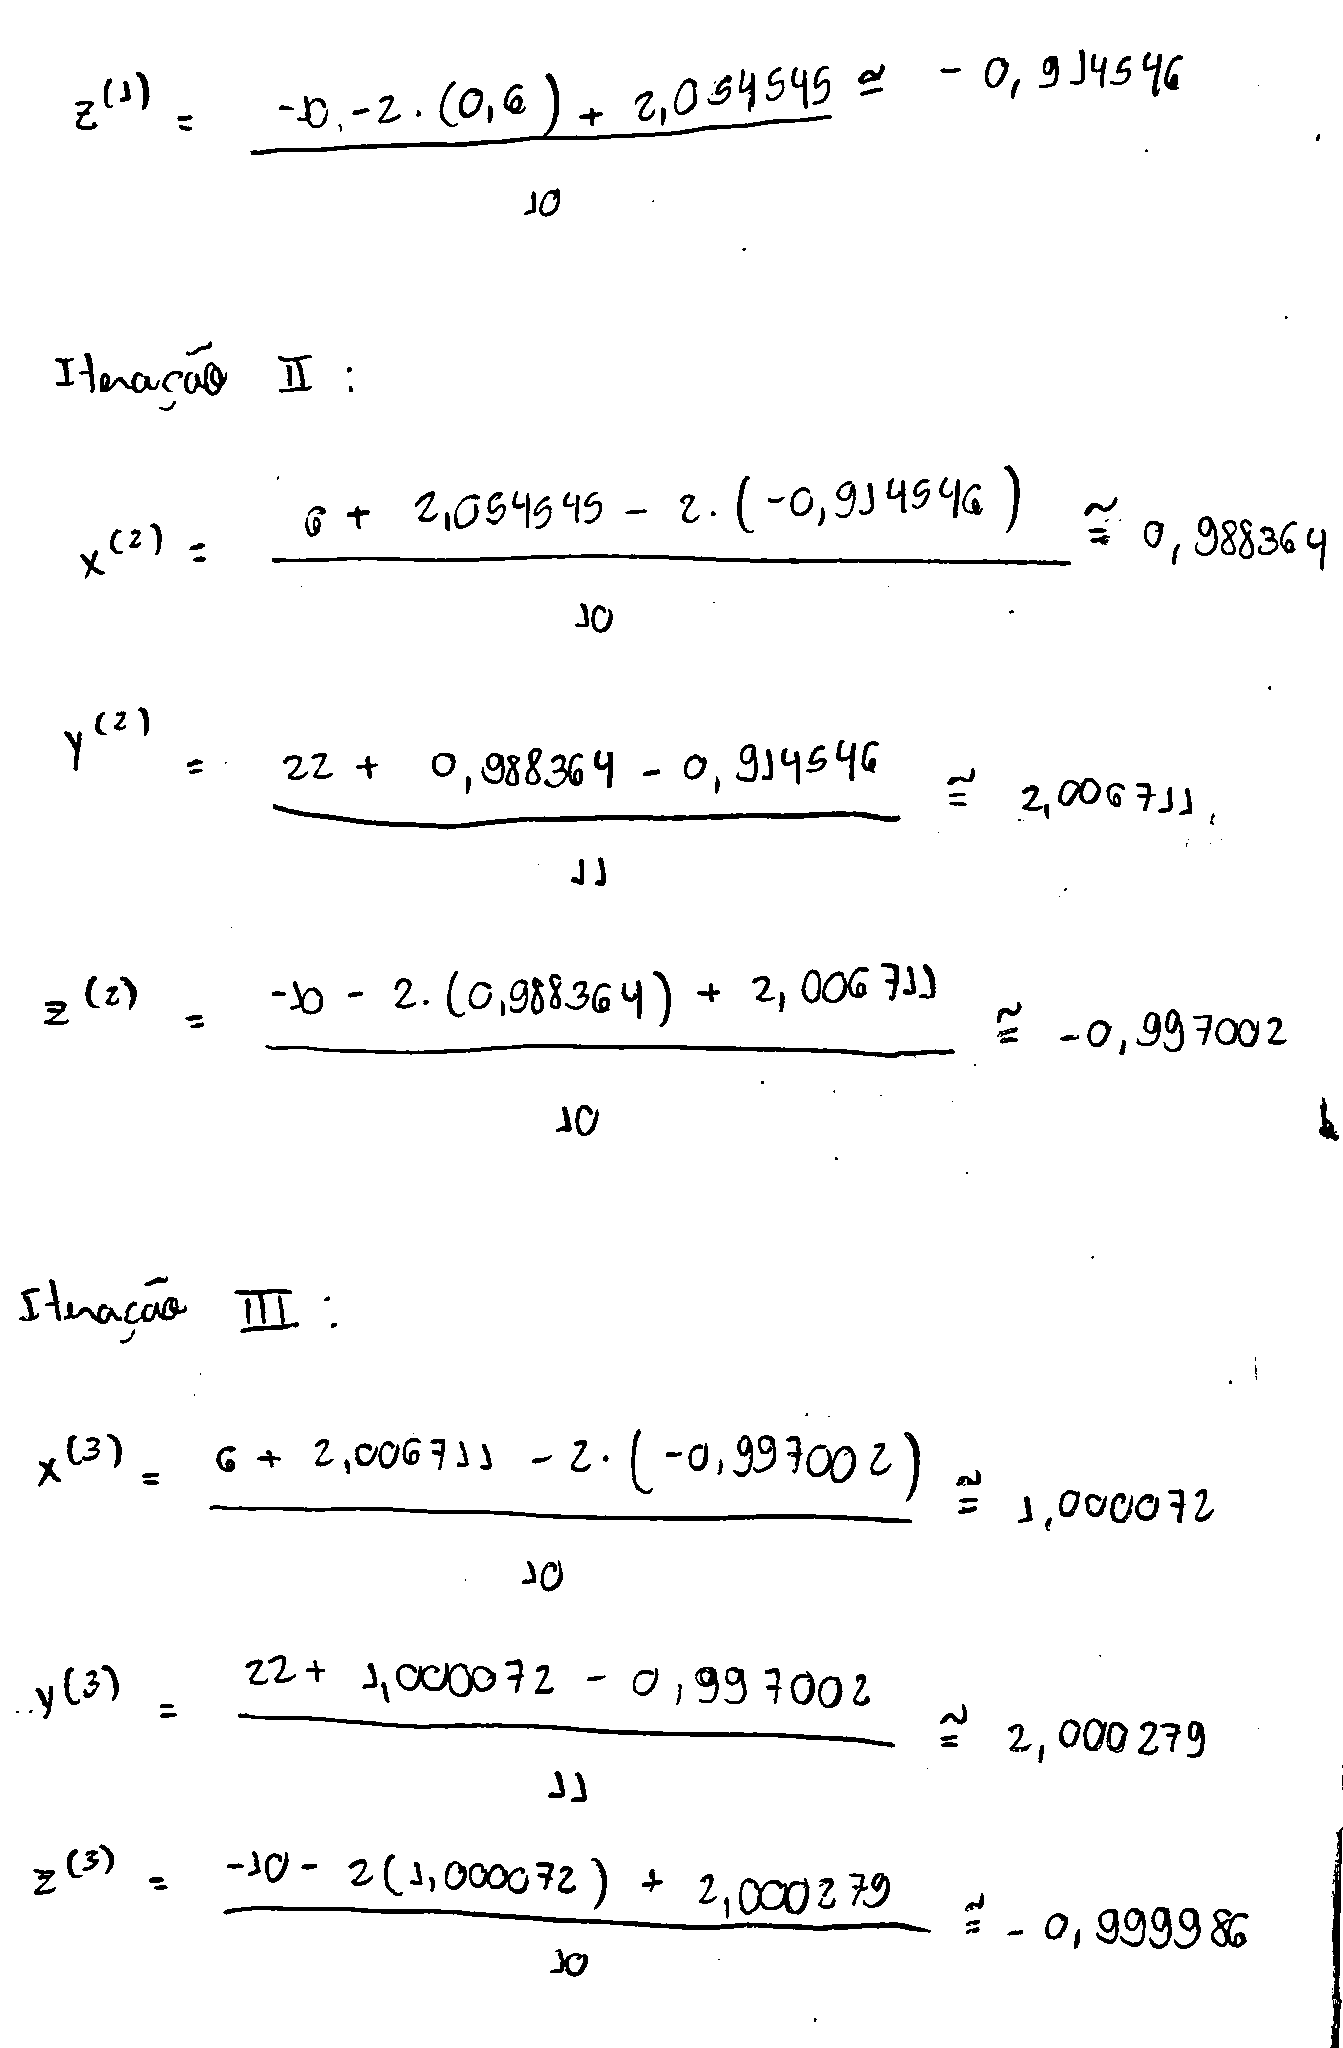



## Questão 5 — Implementação em Python


Critério de parada: $\|\mathbf{x}^{(k)}-\mathbf{x}^{(k-1)}\|_\infty<10^{-5}$.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=9, suppress=True)

A = np.array([
    [10., -1., 2.],
    [-1., 11., -1.],
    [2., -1., 10.]
])
b = np.array([6., 22., -10.])


def gauss_seidel(A, b, tol=1e-5, max_iter=1000):
    A = np.asarray(A, dtype=float)
    b = np.asarray(b, dtype=float)
    n = len(b)
    x = np.zeros(n)
    historico = [x.copy()]
    erros = []

    for k in range(1, max_iter + 1):
        x_anterior = x.copy()

        for i in range(n):
            soma1 = A[i, :i] @ x[:i]
            soma2 = A[i, i+1:] @ x_anterior[i+1:]
            x[i] = (b[i] - soma1 - soma2) / A[i, i]

        erro = np.linalg.norm(x - x_anterior, ord=np.inf)
        historico.append(x.copy())
        erros.append(erro)

        if erro < tol:
            return x, k, np.array(historico), np.array(erros)

    raise RuntimeError("O método não convergiu no limite de iterações.")


x, k, historico, erros = gauss_seidel(A, b)
print("Solução aproximada:", x)
print("Número de iterações:", k)
print("Erro final entre iterações:", erros[-1])


Solução aproximada: [ 1.000000027  1.999999976 -1.000000008]
Número de iterações: 6
Erro final entre iterações: 1.2626069385568428e-06


## Questão 6 — Tabela das iterações

O erro é a norma infinito da diferença entre duas aproximações consecutivas.

In [ ]:
print(f"{'k':>2} {'x':>14} {'y':>14} {'z':>14} {'erro':>14}")
for j in range(len(historico)):
    erro = "-" if j == 0 else f"{erros[j-1]:.6e}"
    print(
        f"{j:2d} "
        f"{historico[j, 0]:14.9f} "
        f"{historico[j, 1]:14.9f} "
        f"{historico[j, 2]:14.9f} "
        f"{erro:>14}"
    )


 k              x              y              z           erro
 0    0.000000000    0.000000000    0.000000000              -
 1    0.600000000    2.054545455   -0.914545455   2.054545e+00
 2    0.988363636    2.006710744   -0.997001653   3.883636e-01
 3    1.000071405    2.000279068   -0.999986374   1.170777e-02
 4    1.000025182    2.000003528   -1.000004684   2.755404e-04
 5    1.000001290    1.999999691   -1.000000289   2.389216e-05
 6    1.000000027    1.999999976   -1.000000008   1.262607e-06


## Questão 7 — Gráficos

### a) Evolução das aproximações

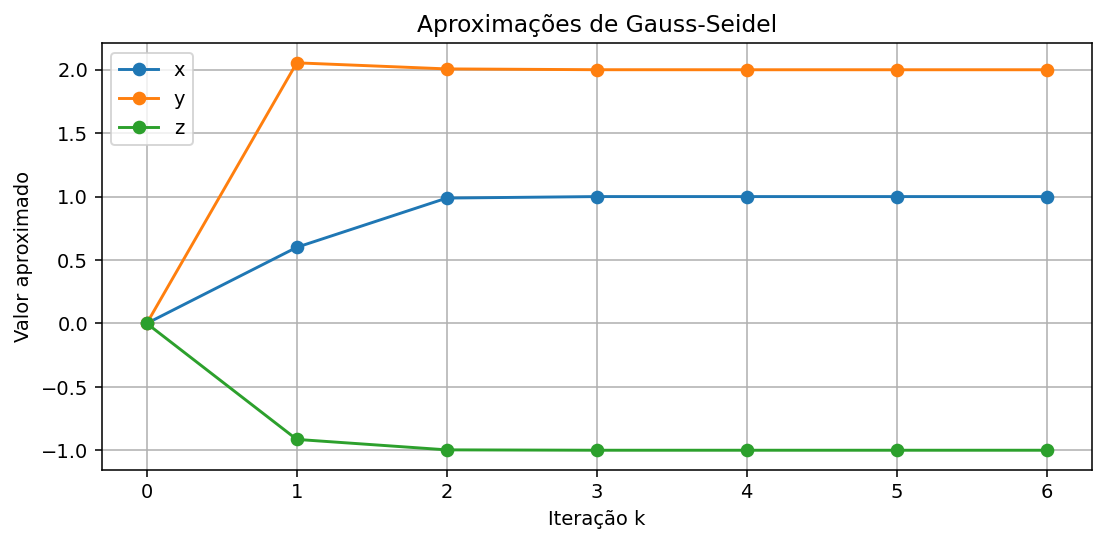

In [ ]:
iteracoes = np.arange(k + 1)
plt.figure(figsize=(8, 4))
plt.plot(iteracoes, historico[:, 0], "o-", label="x")
plt.plot(iteracoes, historico[:, 1], "o-", label="y")
plt.plot(iteracoes, historico[:, 2], "o-", label="z")
plt.xlabel("Iteração k")
plt.ylabel("Valor aproximado")
plt.title("Aproximações de Gauss-Seidel")
plt.xticks(iteracoes)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### b) Erro entre iterações em escala logarítmica

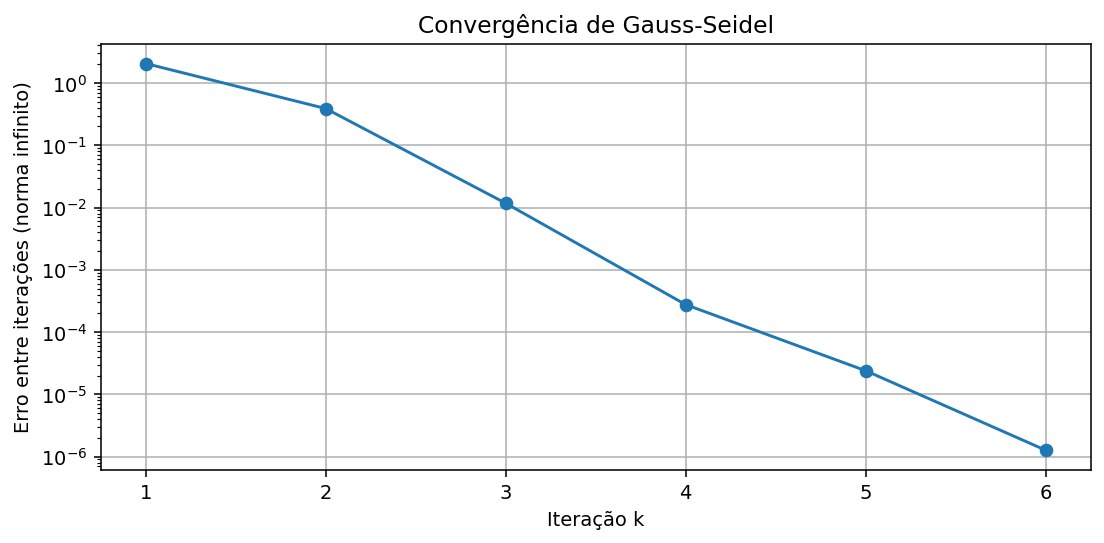

In [ ]:
plt.figure(figsize=(8, 4))
plt.semilogy(iteracoes[1:], erros, "o-")
plt.xlabel("Iteração k")
plt.ylabel("Erro entre iterações (norma infinito)")
plt.title("Convergência de Gauss-Seidel")
plt.xticks(iteracoes[1:])
plt.grid(True)
plt.tight_layout()
plt.show()


O método atinge o critério de parada em **6 iterações**, com solução aproximada $(1,2,-1)$.